# 📊 Evaluasi Data Pipeline — LaLiga Team Style Scoring

---

### Deskripsi Notebook

Notebook ini mengevaluasi kualitas data pipeline dari **Bronze** hingga **Style Scores**.

**Alur Pipeline:**
```
Bronze (12 JSON) → Silver (12 CSV) → Gold OBT (120+ kolom) → ML Features (61 kolom) → Style Scores (9 dimensi)
```

### Daftar Evaluasi

| No | Aspek | Format |
|----|-------|--------|
| 1 | Kelengkapan & Konsistensi Data | Tabel |
| 2 | Kualitas Data (Missing Values, Range) | Tabel |
| 3 | Profil Distribusi Fitur | Gambar |
| 4 | Analisis Korelasi Antar Fitur | Gambar |
| 5 | Evaluasi Normalisasi Min-Max | Gambar |
| 6 | Hasil Style Scores | Gambar |
| 7 | Ringkasan Evaluasi | Tabel |

---
## 1. Setup

In [1]:
import os, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#fafafa',
    'axes.grid': True,
    'grid.alpha': 0.25,
    'font.family': 'sans-serif',
    'font.size': 10,
    'figure.dpi': 150,
})

PALETTE = ['#1a73e8','#34a853','#ea4335','#fbbc04','#9c27b0',
           '#ff6d00','#00bcd4','#795548','#607d8b']

print("✅ Setup selesai.")

✅ Setup selesai.


---
## 2. Load Data

In [2]:
PROJECT_ROOT = Path.cwd().parent
BRONZE_DIR = PROJECT_ROOT / "data" / "bronze" / "teams"
SILVER_DIR = PROJECT_ROOT / "data" / "silver" / "teams" / "csv_clean"
GOLD_DIR   = PROJECT_ROOT / "data" / "gold" / "teams"

TEAM_FILES = [
    "teams_attacking_overall", "teams_attacking_non_penalty",
    "teams_attacking_set_pieces", "teams_attacking_misc",
    "teams_defending_defensive_action", "teams_defending_overall",
    "teams_defending_set_piece", "teams_defending_misc",
    "teams_passing", "teams_pressing", "teams_sequences", "teams_misc",
]

# Bronze
bronze = {}
for name in TEAM_FILES:
    fp = BRONZE_DIR / f"{name}.json"
    if fp.exists():
        with open(fp) as f:
            bronze[name] = json.load(f)

# Silver
silver = {}
for name in TEAM_FILES:
    fp = SILVER_DIR / f"{name}.csv"
    if fp.exists():
        silver[name] = pd.read_csv(fp)

# Gold
df_obt    = pd.read_csv(GOLD_DIR / "teams_statistics.csv")
df_ml     = pd.read_csv(GOLD_DIR / "teams_ml_features.csv")
df_scores = pd.read_csv(GOLD_DIR / "teams_style_scores.csv")

print(f"✅ Data dimuat — Bronze: {len(bronze)}, Silver: {len(silver)}")
print(f"   Gold OBT: {df_obt.shape}, ML Features: {df_ml.shape}, Scores: {df_scores.shape}")

✅ Data dimuat — Bronze: 12, Silver: 12
   Gold OBT: (20, 124), ML Features: (20, 61), Scores: (20, 10)


---
## 3. Evaluasi Kelengkapan & Konsistensi Data

Tabel berikut merangkum **jumlah record dan kolom** di setiap layer pipeline.

> **Format: Tabel**

In [3]:
# --- TABEL 1: Konsistensi Bronze → Silver ---
rows = []
for name in TEAM_FILES:
    b_n = len(bronze[name]) if name in bronze else 0
    b_cols = len(bronze[name][0]) if name in bronze and bronze[name] else 0
    s_n = silver[name].shape[0] if name in silver else 0
    s_cols = silver[name].shape[1] if name in silver else 0
    rows.append({
        "Sub-tabel": name.replace("teams_", ""),
        "Bronze Records": b_n,
        "Bronze Fields": b_cols,
        "Silver Records": s_n,
        "Silver Kolom": s_cols,
        "Konsisten?": "✅" if b_n == s_n == 20 and b_cols == s_cols else "❌",
    })

df_pipeline = pd.DataFrame(rows)

gold_summary = pd.DataFrame([
    {"Layer": "Gold — OBT",         "Records": df_obt.shape[0],    "Kolom": df_obt.shape[1],    "Status": "✅" if df_obt.shape[0]==20 else "❌"},
    {"Layer": "Gold — ML Features", "Records": df_ml.shape[0],     "Kolom": df_ml.shape[1],     "Status": "✅" if df_ml.shape[0]==20 else "❌"},
    {"Layer": "Gold — Style Scores", "Records": df_scores.shape[0], "Kolom": df_scores.shape[1], "Status": "✅" if df_scores.shape[0]==20 else "❌"},
])

print("📋 Tabel 1a: Konsistensi Bronze → Silver")
print("=" * 70)
display(df_pipeline)

print("\n📋 Tabel 1b: Dimensi Data Gold Layer")
print("=" * 50)
display(gold_summary)

obt_cols = set(df_obt.columns) - {'club'}
ml_cols  = set(df_ml.columns) - {'club'}
print(f"\n📌 Feature Reduction: {len(obt_cols)} kolom OBT → {len(ml_cols)} kolom ML Features")
print(f"   Kolom dieliminasi: {len(obt_cols - ml_cols)} ({len(obt_cols - ml_cols)/len(obt_cols)*100:.0f}%)")

📋 Tabel 1a: Konsistensi Bronze → Silver


,Sub-tabel,Bronze Records,Bronze Fields,Silver Records,Silver Kolom,Konsisten?
0,attacking_overall,20,9,20,9,✅
1,attacking_non_penalty,20,9,20,9,✅
2,attacking_set_pieces,20,8,20,8,✅
3,attacking_misc,20,13,20,13,✅
4,defending_defensive_action,20,10,20,10,✅
5,defending_overall,20,11,20,11,✅
6,defending_set_piece,20,8,20,8,✅
7,defending_misc,20,13,20,13,✅
8,passing,20,17,20,17,✅
9,pressing,20,9,20,9,✅



📋 Tabel 1b: Dimensi Data Gold Layer


,Layer,Records,Kolom,Status
0,Gold — OBT,20,124,✅
1,Gold — ML Features,20,61,✅
2,Gold — Style Scores,20,10,✅



📌 Feature Reduction: 123 kolom OBT → 60 kolom ML Features
   Kolom dieliminasi: 63 (51%)


---
## 4. Evaluasi Kualitas Data

Validasi **missing values** dan **range** pada ML Features.

> **Format: Tabel**

In [4]:
# --- TABEL 2: Missing Values & Range ---
num_cols = [c for c in df_ml.columns if c != 'club']
quality_rows = []
for col in num_cols:
    s = df_ml[col]
    is_pct = 'pct' in col
    min_v, max_v = s.min(), s.max()
    nulls = s.isnull().sum()
    if is_pct:
        range_ok = (min_v >= 0) and (max_v <= 100)
    elif 'vs_xg' in col:
        range_ok = True
    else:
        range_ok = min_v >= 0
    quality_rows.append({
        "Kolom": col, "Dtype": str(s.dtype),
        "Min": round(min_v, 2), "Max": round(max_v, 2),
        "Null": nulls, "Range OK": "✅" if range_ok else "❌",
    })

df_quality = pd.DataFrame(quality_rows)
total = len(quality_rows)
ok_range = sum(1 for r in quality_rows if r["Range OK"] == "✅")
ok_null  = sum(1 for r in quality_rows if r["Null"] == 0)

print("📋 Tabel 2: Validasi Kualitas Data — ML Features")
print("=" * 65)
print(f"   Kolom tervalidasi : {total}")
print(f"   Range valid       : {ok_range}/{total}")
print(f"   Tanpa null        : {ok_null}/{total}")
print()
df_quality

📋 Tabel 2: Validasi Kualitas Data — ML Features
   Kolom tervalidasi : 60
   Range valid       : 60/60
   Tanpa null        : 60/60



,Kolom,Dtype,Min,Max,Null,Range OK
0,att_goals,int64,26.00,95.00,0,✅
1,att_xg,float64,30.59,86.62,0,✅
2,att_goals_vs_xg,float64,-12.19,12.96,0,✅
3,att_shots,int64,352.00,692.00,0,✅
4,att_sot,int64,105.00,257.00,0,✅
5,att_conversion_pct,float64,6.91,15.82,0,✅
6,att_xg_per_shot,float64,0.09,0.13,0,✅
7,att_goals_per_game,float64,0.68,2.50,0,✅
8,att_np_goals,int64,24.00,88.00,0,✅
9,att_np_xg,float64,27.43,78.73,0,✅


---
## 5. Profil Distribusi Fitur

Distribusi fitur divisualisasikan per kategori. Setiap gambar = **satu kategori**.

> **Format: Gambar**

### Kategori: Attacking (`att_`)

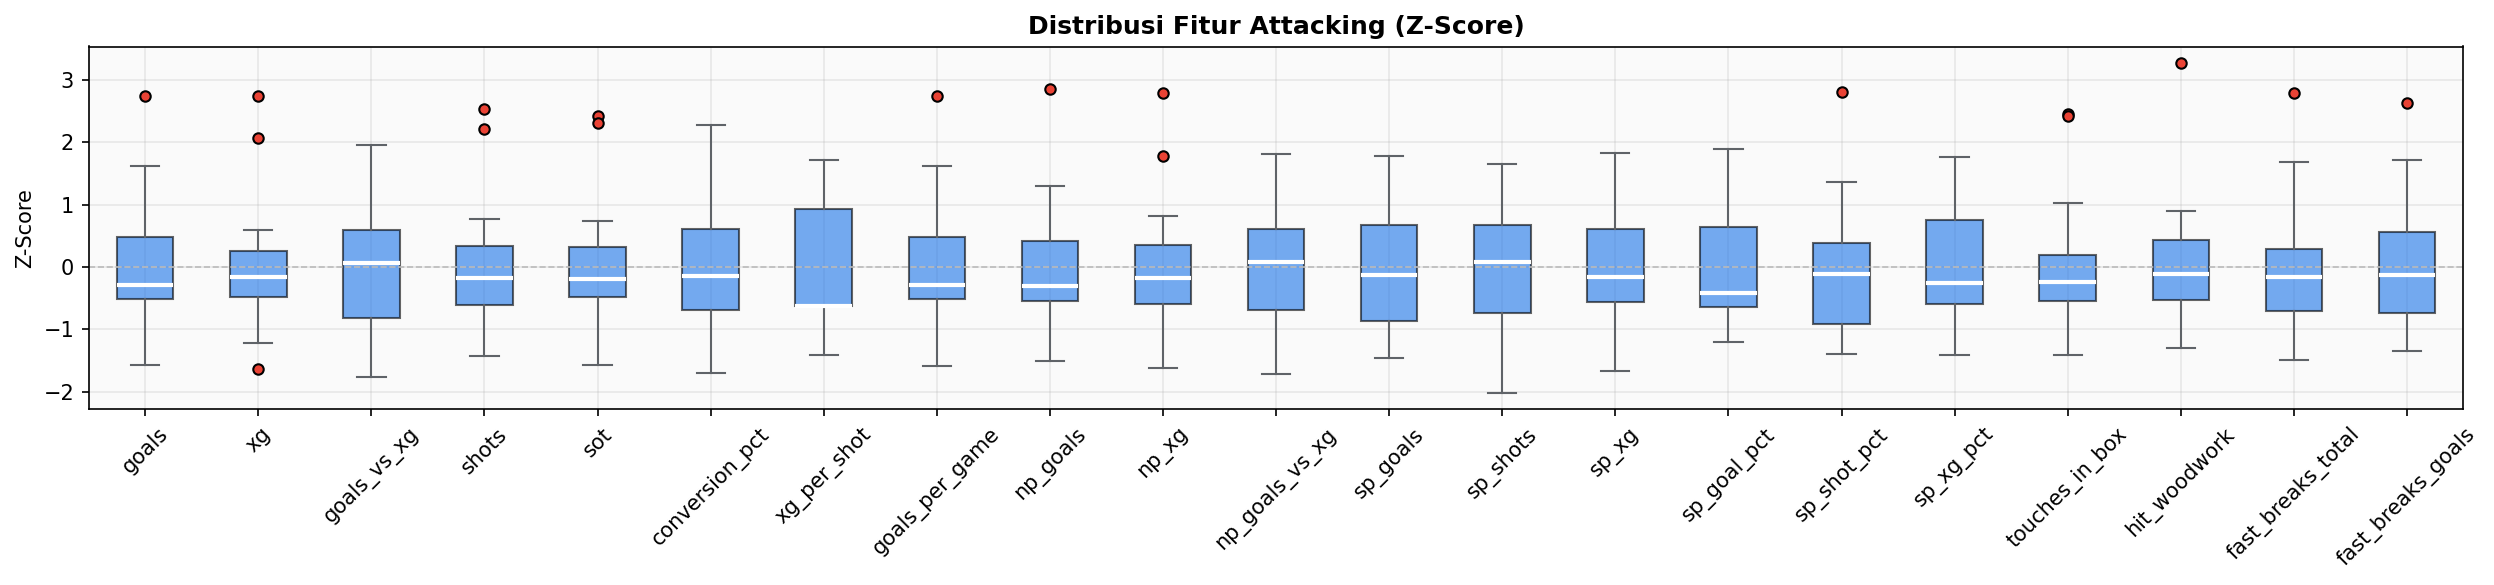

   Jumlah fitur: 21


In [5]:
cols = [c for c in df_ml.columns if c.startswith('att_')]
data_z = df_ml[cols].apply(lambda x: (x - x.mean()) / x.std())

fig, ax = plt.subplots(figsize=(max(len(cols)*0.8, 6), 4))
bp = ax.boxplot([data_z[c].values for c in cols],
    labels=[c.replace('att_', '') for c in cols],
    patch_artist=True, medianprops=dict(color='white', linewidth=2),
    whiskerprops=dict(color='#5f6368'), capprops=dict(color='#5f6368'),
    flierprops=dict(marker='o', markerfacecolor='#ea4335', markersize=5))
for p in bp['boxes']: p.set_facecolor(PALETTE[0]); p.set_alpha(0.6)
ax.set_title('Distribusi Fitur Attacking (Z-Score)', fontweight='bold', fontsize=12)
ax.set_ylabel('Z-Score')
ax.axhline(y=0, color='#bbb', ls='--', lw=0.8)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
print(f"   Jumlah fitur: {len(cols)}")

### Kategori: Defending (`def_`)

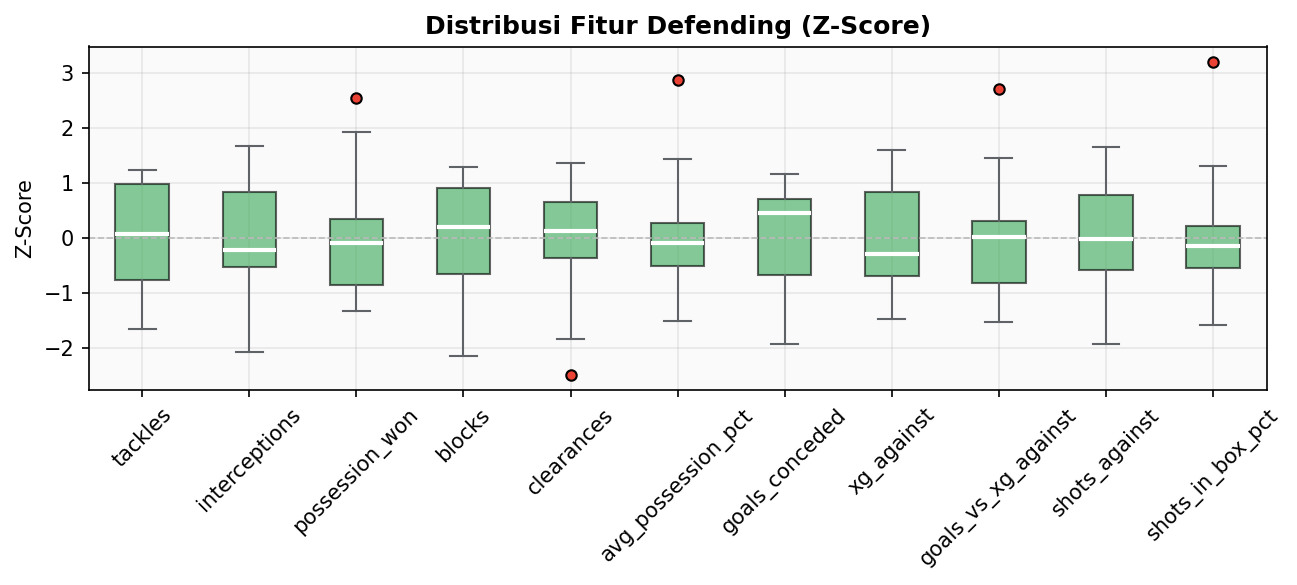

   Jumlah fitur: 11


In [6]:
cols = [c for c in df_ml.columns if c.startswith('def_')]
data_z = df_ml[cols].apply(lambda x: (x - x.mean()) / x.std())

fig, ax = plt.subplots(figsize=(max(len(cols)*0.8, 6), 4))
bp = ax.boxplot([data_z[c].values for c in cols],
    labels=[c.replace('def_', '') for c in cols],
    patch_artist=True, medianprops=dict(color='white', linewidth=2),
    whiskerprops=dict(color='#5f6368'), capprops=dict(color='#5f6368'),
    flierprops=dict(marker='o', markerfacecolor='#ea4335', markersize=5))
for p in bp['boxes']: p.set_facecolor(PALETTE[1]); p.set_alpha(0.6)
ax.set_title('Distribusi Fitur Defending (Z-Score)', fontweight='bold', fontsize=12)
ax.set_ylabel('Z-Score')
ax.axhline(y=0, color='#bbb', ls='--', lw=0.8)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
print(f"   Jumlah fitur: {len(cols)}")

### Kategori: Passing (`pas_`)

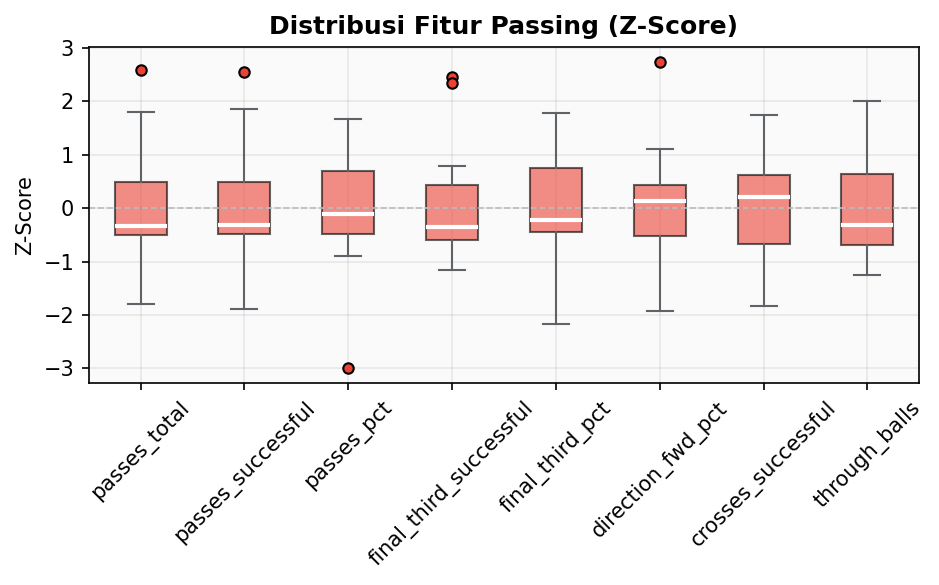

   Jumlah fitur: 8


In [7]:
cols = [c for c in df_ml.columns if c.startswith('pas_')]
data_z = df_ml[cols].apply(lambda x: (x - x.mean()) / x.std())

fig, ax = plt.subplots(figsize=(max(len(cols)*0.8, 6), 4))
bp = ax.boxplot([data_z[c].values for c in cols],
    labels=[c.replace('pas_', '') for c in cols],
    patch_artist=True, medianprops=dict(color='white', linewidth=2),
    whiskerprops=dict(color='#5f6368'), capprops=dict(color='#5f6368'),
    flierprops=dict(marker='o', markerfacecolor='#ea4335', markersize=5))
for p in bp['boxes']: p.set_facecolor(PALETTE[2]); p.set_alpha(0.6)
ax.set_title('Distribusi Fitur Passing (Z-Score)', fontweight='bold', fontsize=12)
ax.set_ylabel('Z-Score')
ax.axhline(y=0, color='#bbb', ls='--', lw=0.8)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
print(f"   Jumlah fitur: {len(cols)}")

### Kategori: Pressing (`prs_`)

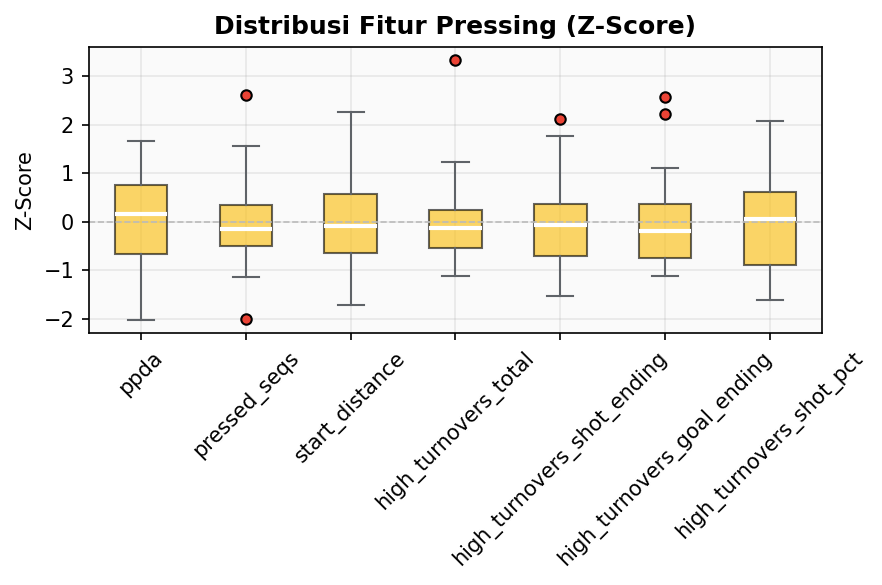

   Jumlah fitur: 7


In [8]:
cols = [c for c in df_ml.columns if c.startswith('prs_')]
data_z = df_ml[cols].apply(lambda x: (x - x.mean()) / x.std())

fig, ax = plt.subplots(figsize=(max(len(cols)*0.8, 6), 4))
bp = ax.boxplot([data_z[c].values for c in cols],
    labels=[c.replace('prs_', '') for c in cols],
    patch_artist=True, medianprops=dict(color='white', linewidth=2),
    whiskerprops=dict(color='#5f6368'), capprops=dict(color='#5f6368'),
    flierprops=dict(marker='o', markerfacecolor='#ea4335', markersize=5))
for p in bp['boxes']: p.set_facecolor(PALETTE[3]); p.set_alpha(0.6)
ax.set_title('Distribusi Fitur Pressing (Z-Score)', fontweight='bold', fontsize=12)
ax.set_ylabel('Z-Score')
ax.axhline(y=0, color='#bbb', ls='--', lw=0.8)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
print(f"   Jumlah fitur: {len(cols)}")

### Kategori: Sequences (`seq_`)

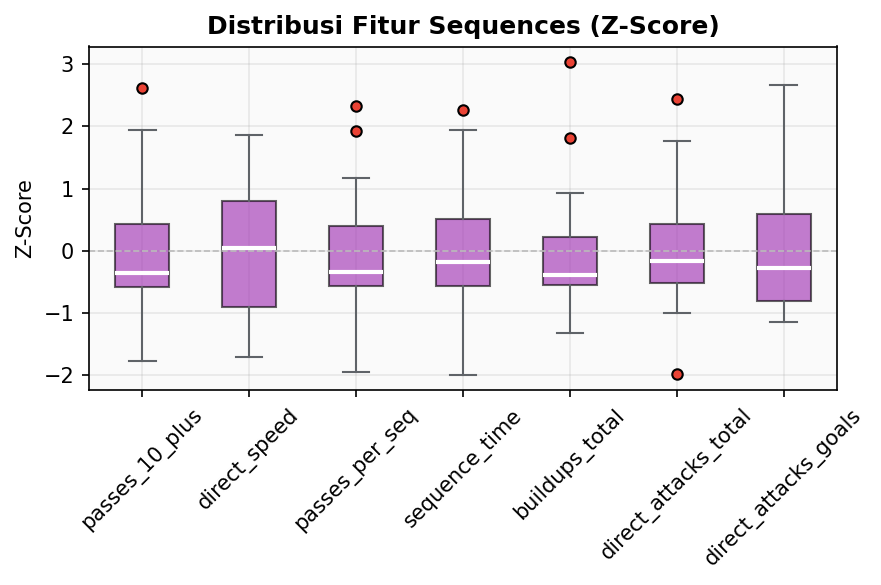

   Jumlah fitur: 7


In [9]:
cols = [c for c in df_ml.columns if c.startswith('seq_')]
data_z = df_ml[cols].apply(lambda x: (x - x.mean()) / x.std())

fig, ax = plt.subplots(figsize=(max(len(cols)*0.8, 6), 4))
bp = ax.boxplot([data_z[c].values for c in cols],
    labels=[c.replace('seq_', '') for c in cols],
    patch_artist=True, medianprops=dict(color='white', linewidth=2),
    whiskerprops=dict(color='#5f6368'), capprops=dict(color='#5f6368'),
    flierprops=dict(marker='o', markerfacecolor='#ea4335', markersize=5))
for p in bp['boxes']: p.set_facecolor(PALETTE[4]); p.set_alpha(0.6)
ax.set_title('Distribusi Fitur Sequences (Z-Score)', fontweight='bold', fontsize=12)
ax.set_ylabel('Z-Score')
ax.axhline(y=0, color='#bbb', ls='--', lw=0.8)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
print(f"   Jumlah fitur: {len(cols)}")

### Kategori: Miscellaneous (`msc_`)

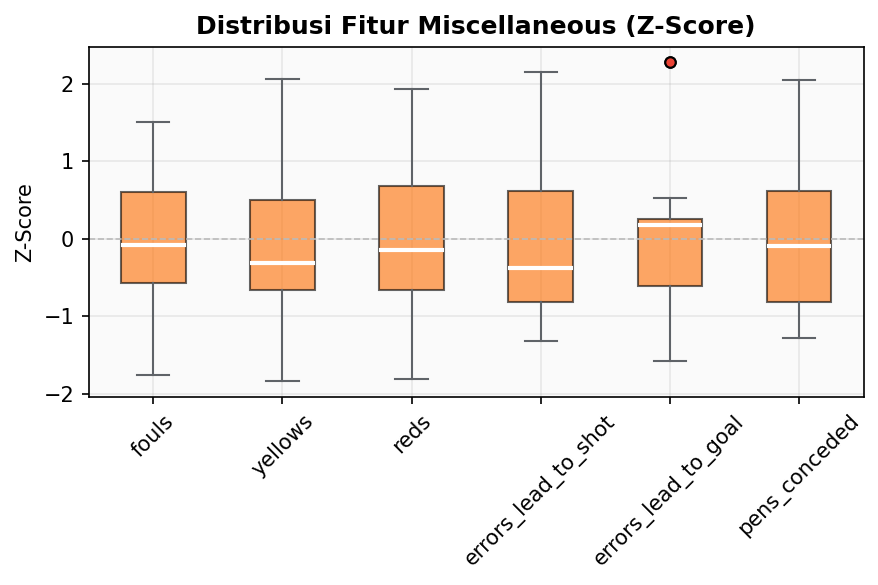

   Jumlah fitur: 6


In [10]:
cols = [c for c in df_ml.columns if c.startswith('msc_')]
data_z = df_ml[cols].apply(lambda x: (x - x.mean()) / x.std())

fig, ax = plt.subplots(figsize=(max(len(cols)*0.8, 6), 4))
bp = ax.boxplot([data_z[c].values for c in cols],
    labels=[c.replace('msc_', '') for c in cols],
    patch_artist=True, medianprops=dict(color='white', linewidth=2),
    whiskerprops=dict(color='#5f6368'), capprops=dict(color='#5f6368'),
    flierprops=dict(marker='o', markerfacecolor='#ea4335', markersize=5))
for p in bp['boxes']: p.set_facecolor(PALETTE[5]); p.set_alpha(0.6)
ax.set_title('Distribusi Fitur Miscellaneous (Z-Score)', fontweight='bold', fontsize=12)
ax.set_ylabel('Z-Score')
ax.axhline(y=0, color='#bbb', ls='--', lw=0.8)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
print(f"   Jumlah fitur: {len(cols)}")

---
## 6. Analisis Korelasi Antar Fitur

Correlation heatmap untuk mendeteksi **redundansi** antar fitur.

> **Format: Gambar**

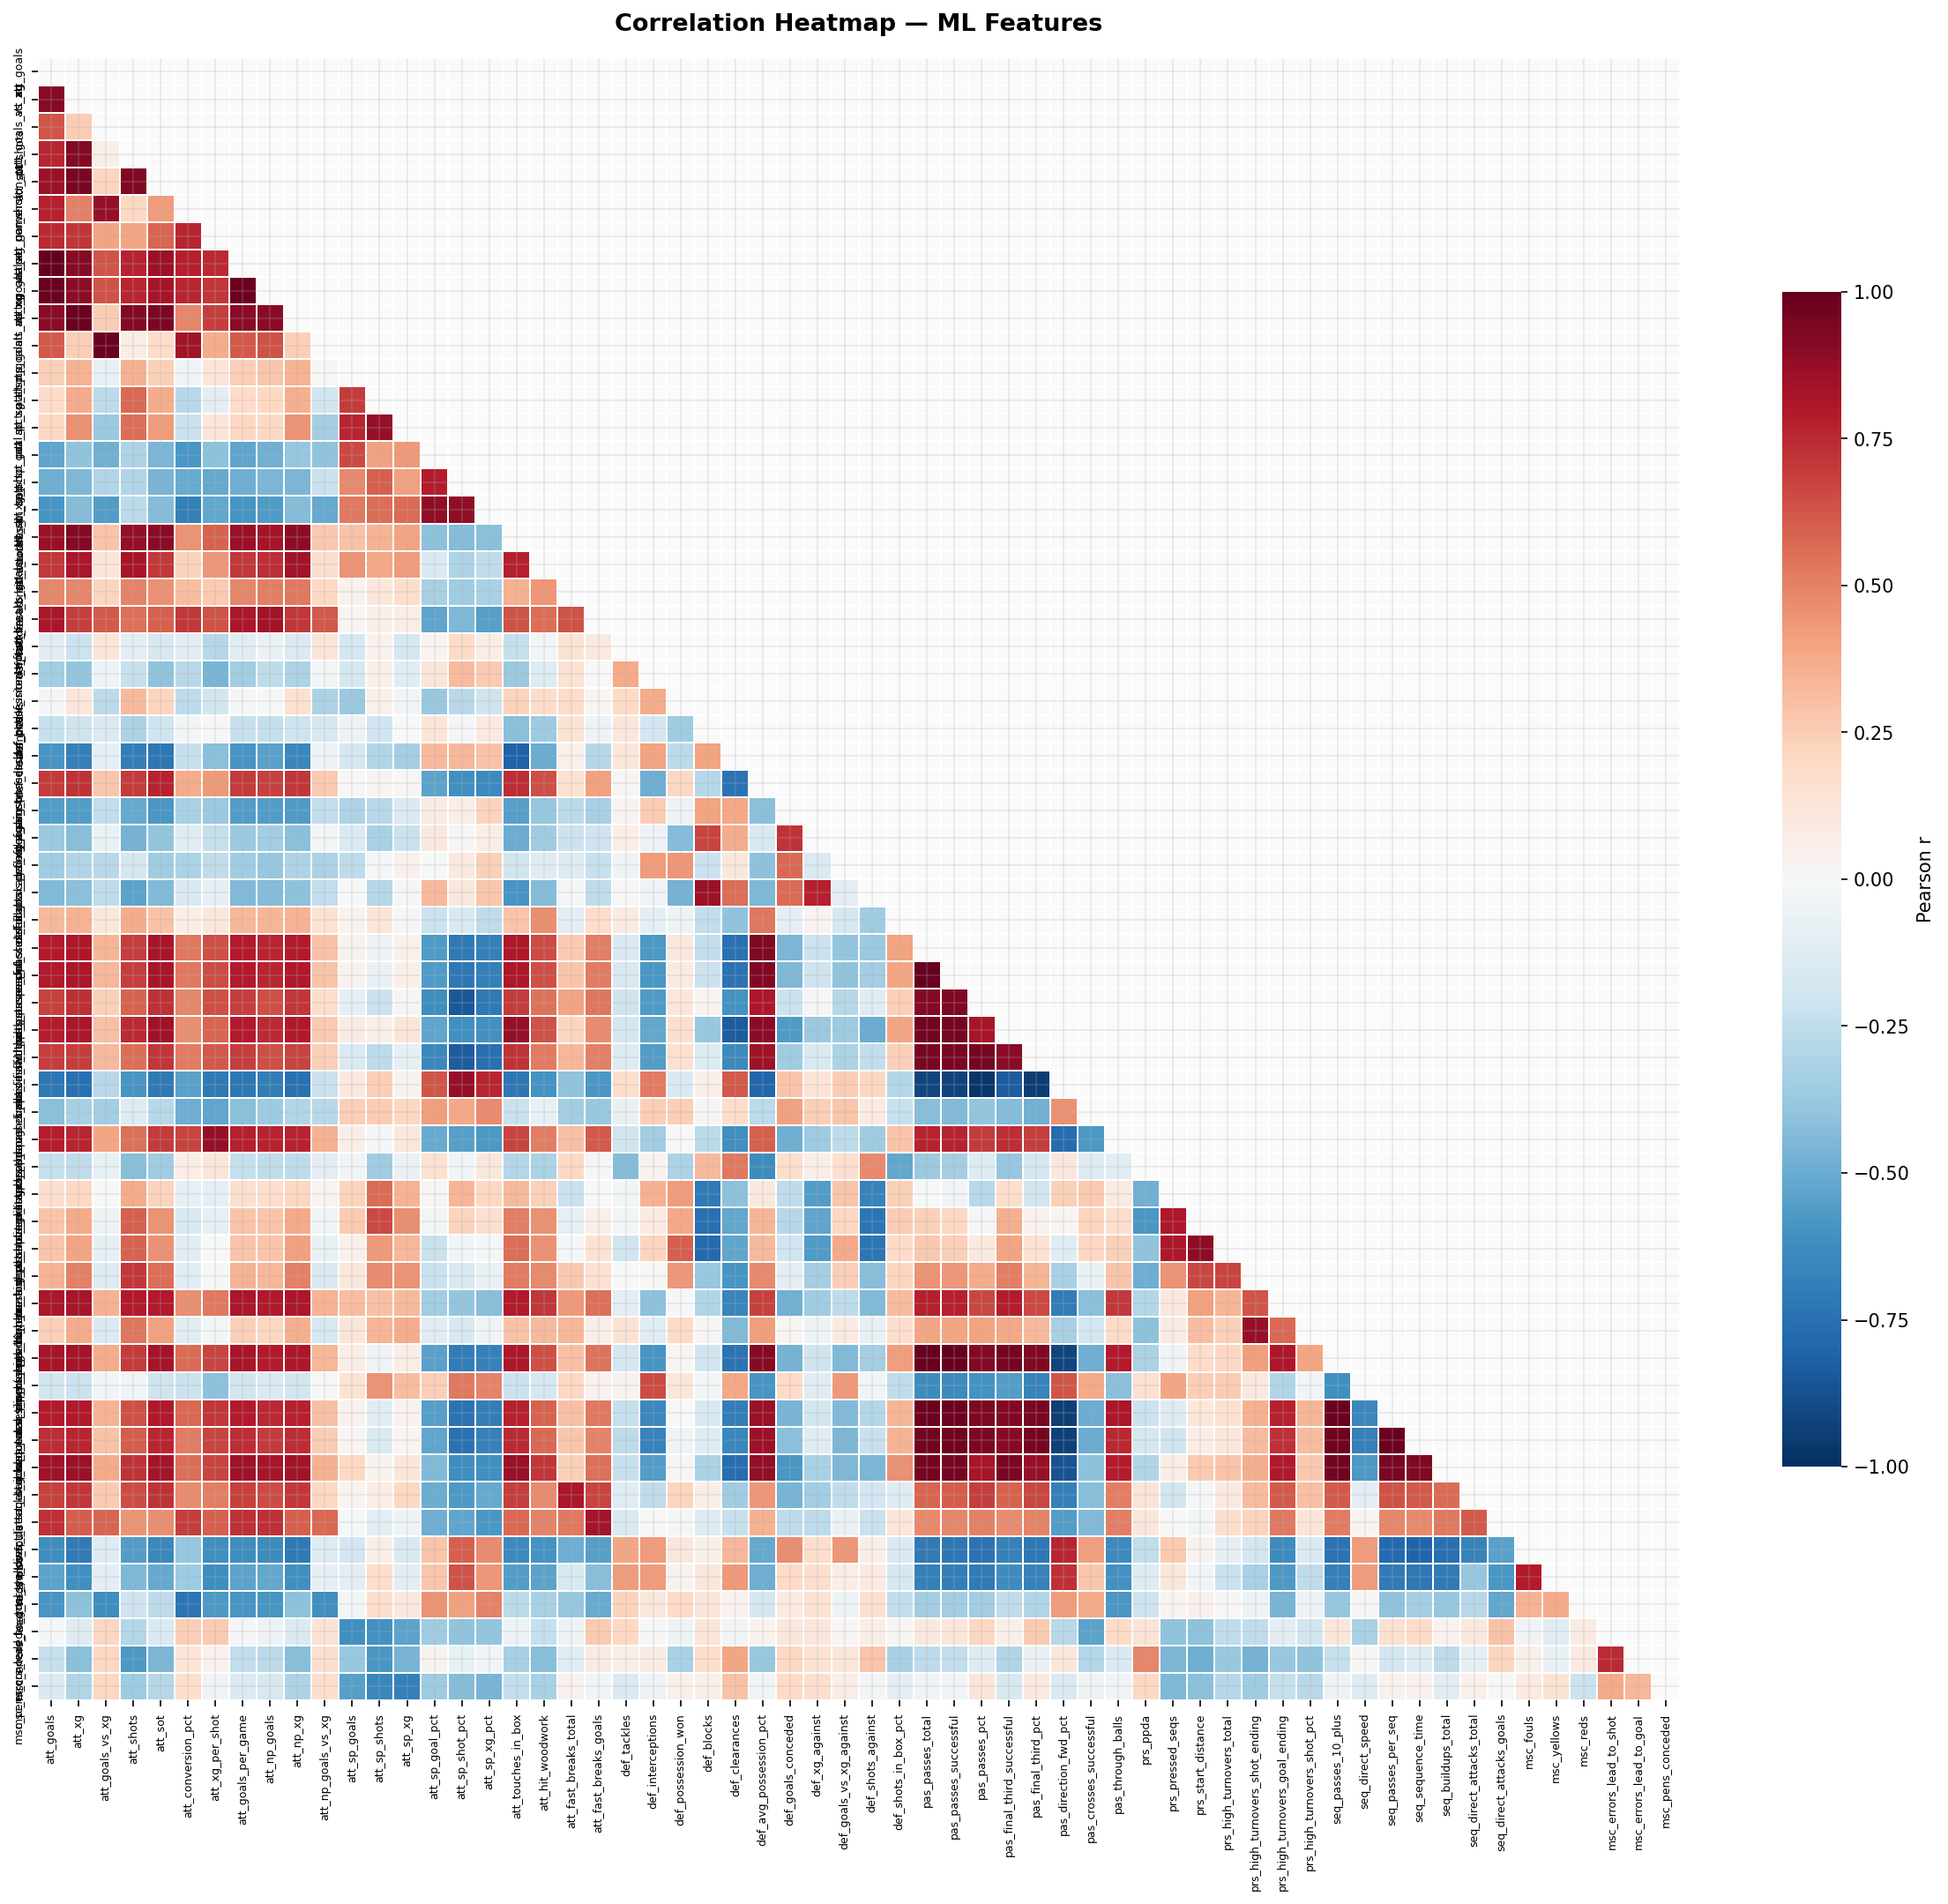


📋 Pasangan dengan |r| > 0.85: 85


,Fitur 1,Fitur 2,|r|
0,att_goals,att_goals_per_game,1.00
1,pas_passes_total,pas_passes_successful,1.00
2,pas_passes_successful,seq_passes_10_plus,0.99
3,pas_passes_total,seq_passes_10_plus,0.99
4,att_xg,att_np_xg,0.99
...,...,...,...
80,def_avg_possession_pct,seq_sequence_time,0.86
81,att_xg,seq_buildups_total,0.85
82,att_sot,att_goals_per_game,0.85
83,att_goals,att_sot,0.85


In [11]:
num_cols = [c for c in df_ml.columns if c != 'club']
corr = df_ml[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.2, linecolor='white', annot=False, ax=ax,
            cbar_kws={'label': 'Pearson r', 'shrink': 0.7})
ax.set_title('Correlation Heatmap — ML Features', fontsize=13, fontweight='bold', pad=15)
ax.tick_params(axis='both', labelsize=6, rotation=90)
plt.tight_layout()
plt.show()

# Pasangan korelasi tinggi
pairs = []
for i in range(len(corr)):
    for j in range(i+1, len(corr)):
        r = corr.iloc[i,j]
        if abs(r) > 0.85:
            pairs.append({"Fitur 1": corr.columns[i], "Fitur 2": corr.columns[j], "|r|": round(abs(r),3)})

print(f"\n📋 Pasangan dengan |r| > 0.85: {len(pairs)}")
if pairs:
    display(pd.DataFrame(pairs).sort_values("|r|", ascending=False).reset_index(drop=True))

---
## 7. Evaluasi Normalisasi Min-Max

Perbandingan distribusi **sebelum dan sesudah** normalisasi. Setiap gambar = **satu style dimension**.

> **Format: Gambar**

In [12]:
# Helper
def minmax_norm(s, inverse=False):
    mn, mx = s.min(), s.max()
    if mx == mn: return pd.Series(50.0, index=s.index)
    n = (s - mn) / (mx - mn) * 100
    return 100 - n if inverse else n

STYLE_CFG = {
    "Possession": {
        "cols": ["def_avg_possession_pct","pas_passes_total","pas_passes_successful","pas_passes_pct",
                 "pas_final_third_pct","seq_passes_10_plus","seq_passes_per_seq","seq_sequence_time"],
        "inverse": [],
    },
    "Pressing": {
        "cols": ["prs_ppda","prs_pressed_seqs","prs_high_turnovers_total",
                 "prs_high_turnovers_shot_ending","prs_high_turnovers_goal_ending","prs_high_turnovers_shot_pct","prs_start_distance"],
        "inverse": ["prs_ppda"],
    },
    "Defensive Solidity": {
        "cols": ["def_goals_conceded","def_xg_against","def_shots_against","def_shots_in_box_pct",
                 "def_tackles","def_interceptions","def_blocks","def_clearances","def_possession_won","def_goals_vs_xg_against"],
        "inverse": ["def_goals_conceded","def_xg_against","def_shots_against","def_shots_in_box_pct"],
    },
}
print("✅ Config dimuat untuk 3 sample styles.")

✅ Config dimuat untuk 3 sample styles.


### Before vs After: Possession

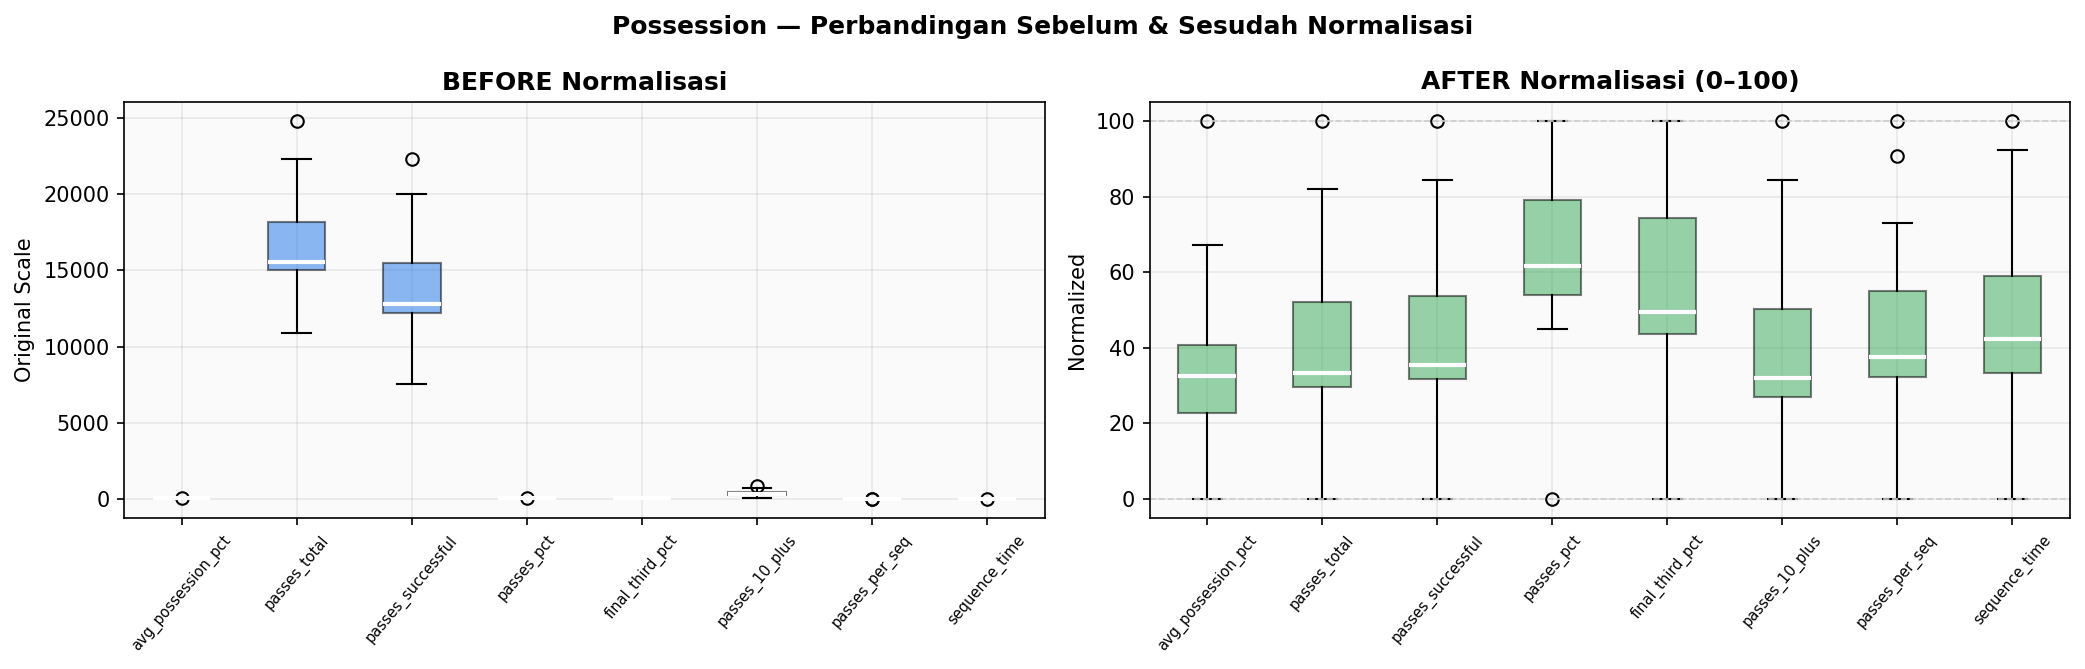

In [13]:
cfg = STYLE_CFG["Possession"]
cols = cfg["cols"]
short = [c.split('_',1)[1] for c in cols]
raw = df_ml[cols]
normed = pd.DataFrame({c: minmax_norm(df_ml[c], c in cfg["inverse"]) for c in cols})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
bp1 = ax1.boxplot([raw[c].values for c in cols], labels=short, patch_artist=True,
                   medianprops=dict(color='white', linewidth=2))
for p in bp1['boxes']: p.set_facecolor('#1a73e8'); p.set_alpha(0.5)
ax1.set_title('BEFORE Normalisasi', fontweight='bold')
ax1.set_ylabel('Original Scale')
ax1.tick_params(axis='x', rotation=50, labelsize=7)

bp2 = ax2.boxplot([normed[c].values for c in cols], labels=short, patch_artist=True,
                   medianprops=dict(color='white', linewidth=2))
for p in bp2['boxes']: p.set_facecolor('#34a853'); p.set_alpha(0.5)
ax2.set_title('AFTER Normalisasi (0–100)', fontweight='bold')
ax2.set_ylabel('Normalized')
ax2.set_ylim(-5, 105)
ax2.axhline(0, color='#ccc', ls='--', lw=0.8)
ax2.axhline(100, color='#ccc', ls='--', lw=0.8)
ax2.tick_params(axis='x', rotation=50, labelsize=7)

fig.suptitle('Possession — Perbandingan Sebelum & Sesudah Normalisasi', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

### Before vs After: Pressing

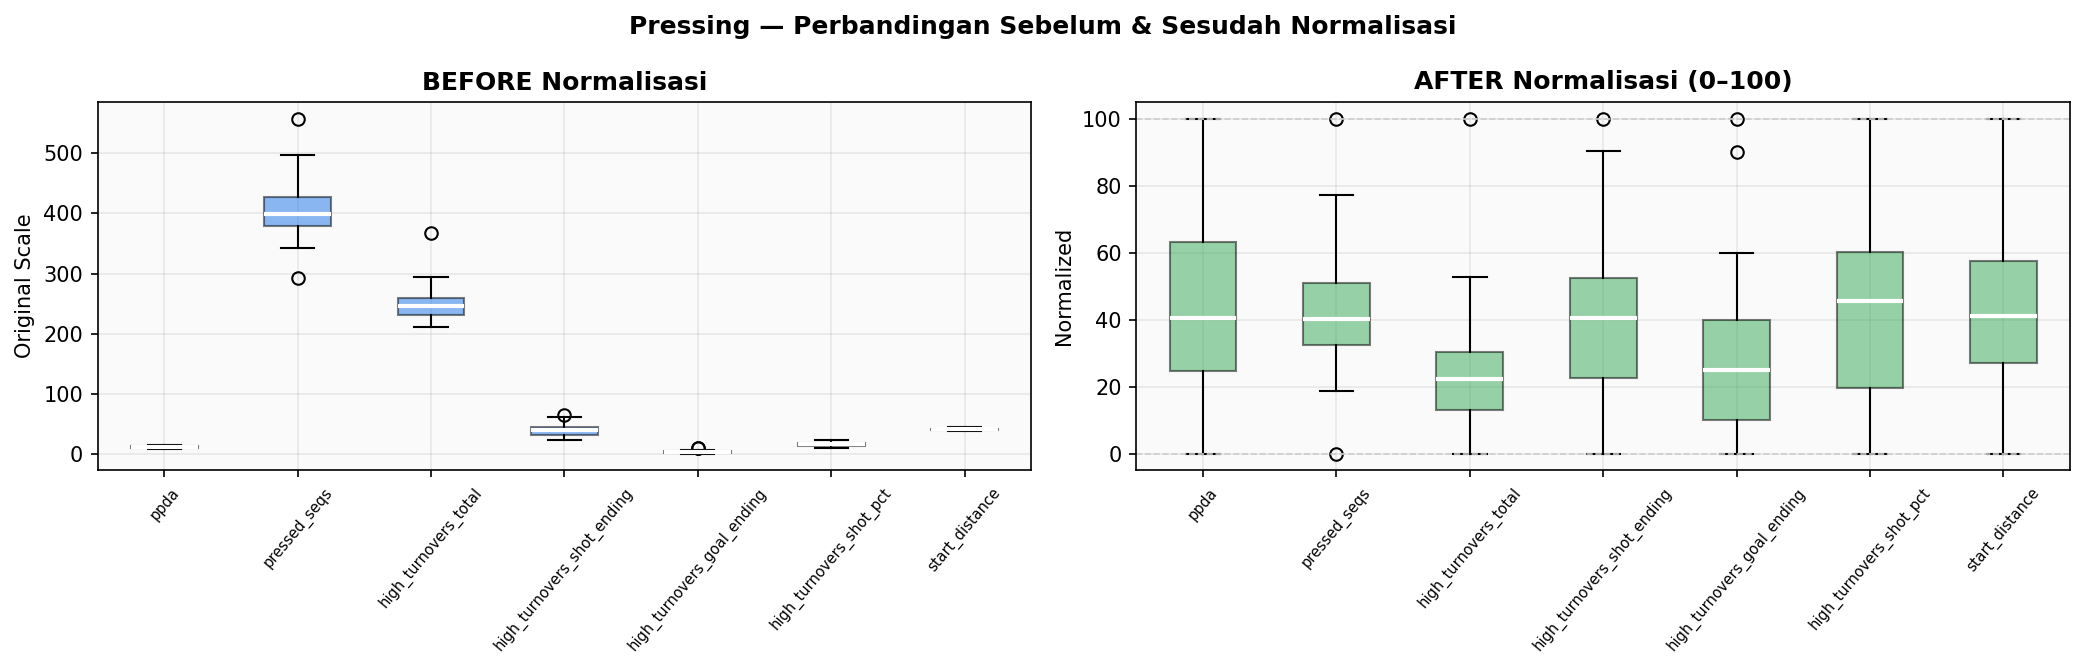

In [14]:
cfg = STYLE_CFG["Pressing"]
cols = cfg["cols"]
short = [c.split('_',1)[1] for c in cols]
raw = df_ml[cols]
normed = pd.DataFrame({c: minmax_norm(df_ml[c], c in cfg["inverse"]) for c in cols})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
bp1 = ax1.boxplot([raw[c].values for c in cols], labels=short, patch_artist=True,
                   medianprops=dict(color='white', linewidth=2))
for p in bp1['boxes']: p.set_facecolor('#1a73e8'); p.set_alpha(0.5)
ax1.set_title('BEFORE Normalisasi', fontweight='bold')
ax1.set_ylabel('Original Scale')
ax1.tick_params(axis='x', rotation=50, labelsize=7)

bp2 = ax2.boxplot([normed[c].values for c in cols], labels=short, patch_artist=True,
                   medianprops=dict(color='white', linewidth=2))
for p in bp2['boxes']: p.set_facecolor('#34a853'); p.set_alpha(0.5)
ax2.set_title('AFTER Normalisasi (0–100)', fontweight='bold')
ax2.set_ylabel('Normalized')
ax2.set_ylim(-5, 105)
ax2.axhline(0, color='#ccc', ls='--', lw=0.8)
ax2.axhline(100, color='#ccc', ls='--', lw=0.8)
ax2.tick_params(axis='x', rotation=50, labelsize=7)

fig.suptitle('Pressing — Perbandingan Sebelum & Sesudah Normalisasi', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

### Before vs After: Defensive Solidity

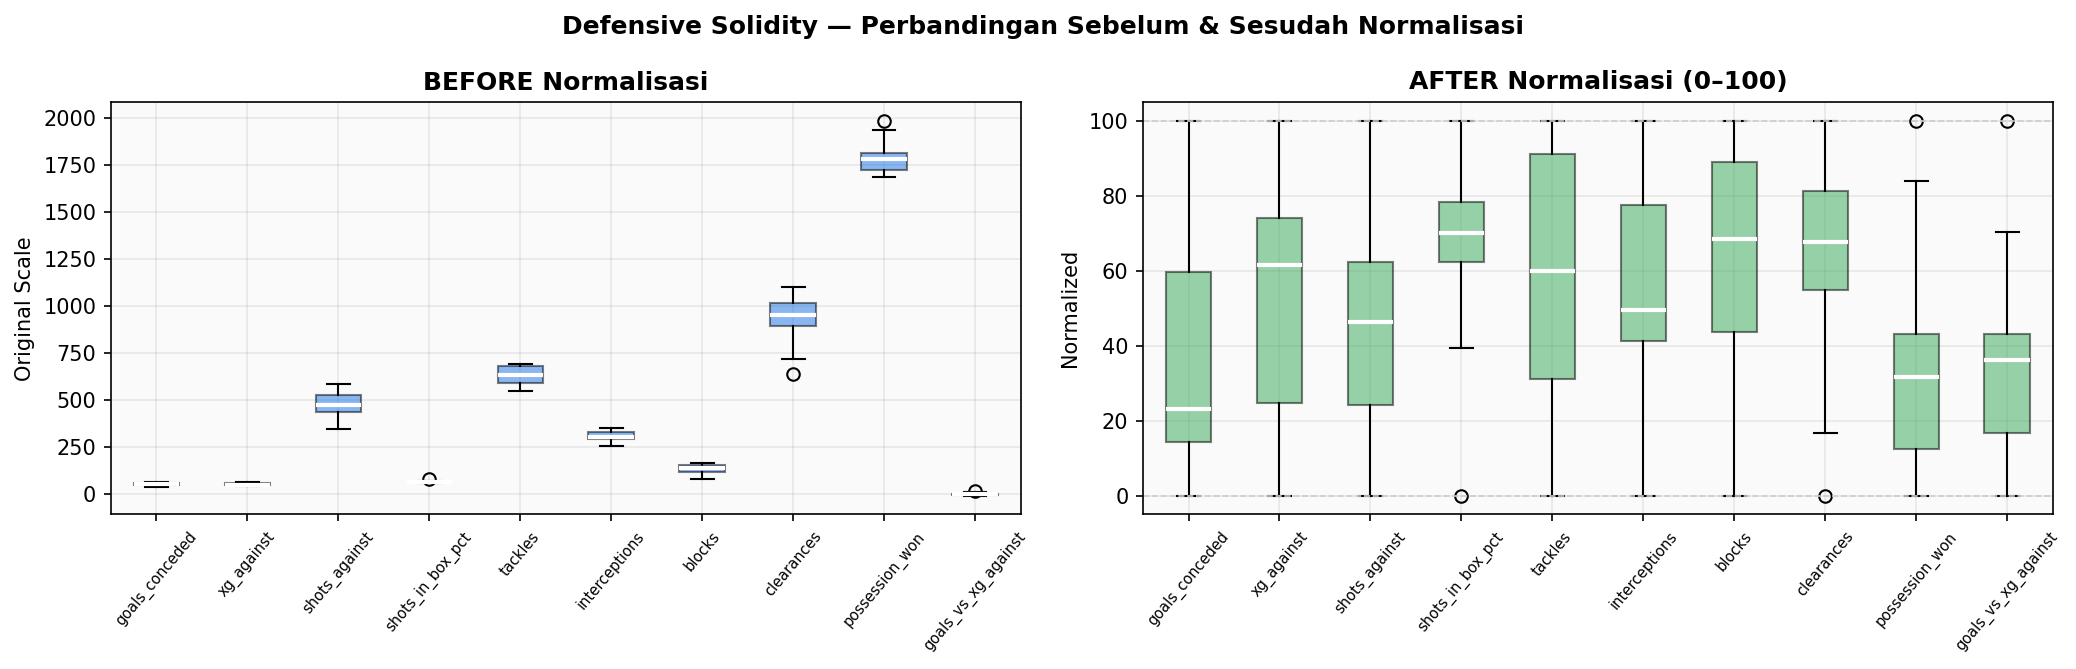

In [15]:
cfg = STYLE_CFG["Defensive Solidity"]
cols = cfg["cols"]
short = [c.split('_',1)[1] for c in cols]
raw = df_ml[cols]
normed = pd.DataFrame({c: minmax_norm(df_ml[c], c in cfg["inverse"]) for c in cols})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
bp1 = ax1.boxplot([raw[c].values for c in cols], labels=short, patch_artist=True,
                   medianprops=dict(color='white', linewidth=2))
for p in bp1['boxes']: p.set_facecolor('#1a73e8'); p.set_alpha(0.5)
ax1.set_title('BEFORE Normalisasi', fontweight='bold')
ax1.set_ylabel('Original Scale')
ax1.tick_params(axis='x', rotation=50, labelsize=7)

bp2 = ax2.boxplot([normed[c].values for c in cols], labels=short, patch_artist=True,
                   medianprops=dict(color='white', linewidth=2))
for p in bp2['boxes']: p.set_facecolor('#34a853'); p.set_alpha(0.5)
ax2.set_title('AFTER Normalisasi (0–100)', fontweight='bold')
ax2.set_ylabel('Normalized')
ax2.set_ylim(-5, 105)
ax2.axhline(0, color='#ccc', ls='--', lw=0.8)
ax2.axhline(100, color='#ccc', ls='--', lw=0.8)
ax2.tick_params(axis='x', rotation=50, labelsize=7)

fig.suptitle('Defensive Solidity — Perbandingan Sebelum & Sesudah Normalisasi', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

---
## 8. Hasil Style Scores

Heatmap skor akhir 20 tim × 9 dimensi gaya bermain.

> **Format: Gambar**

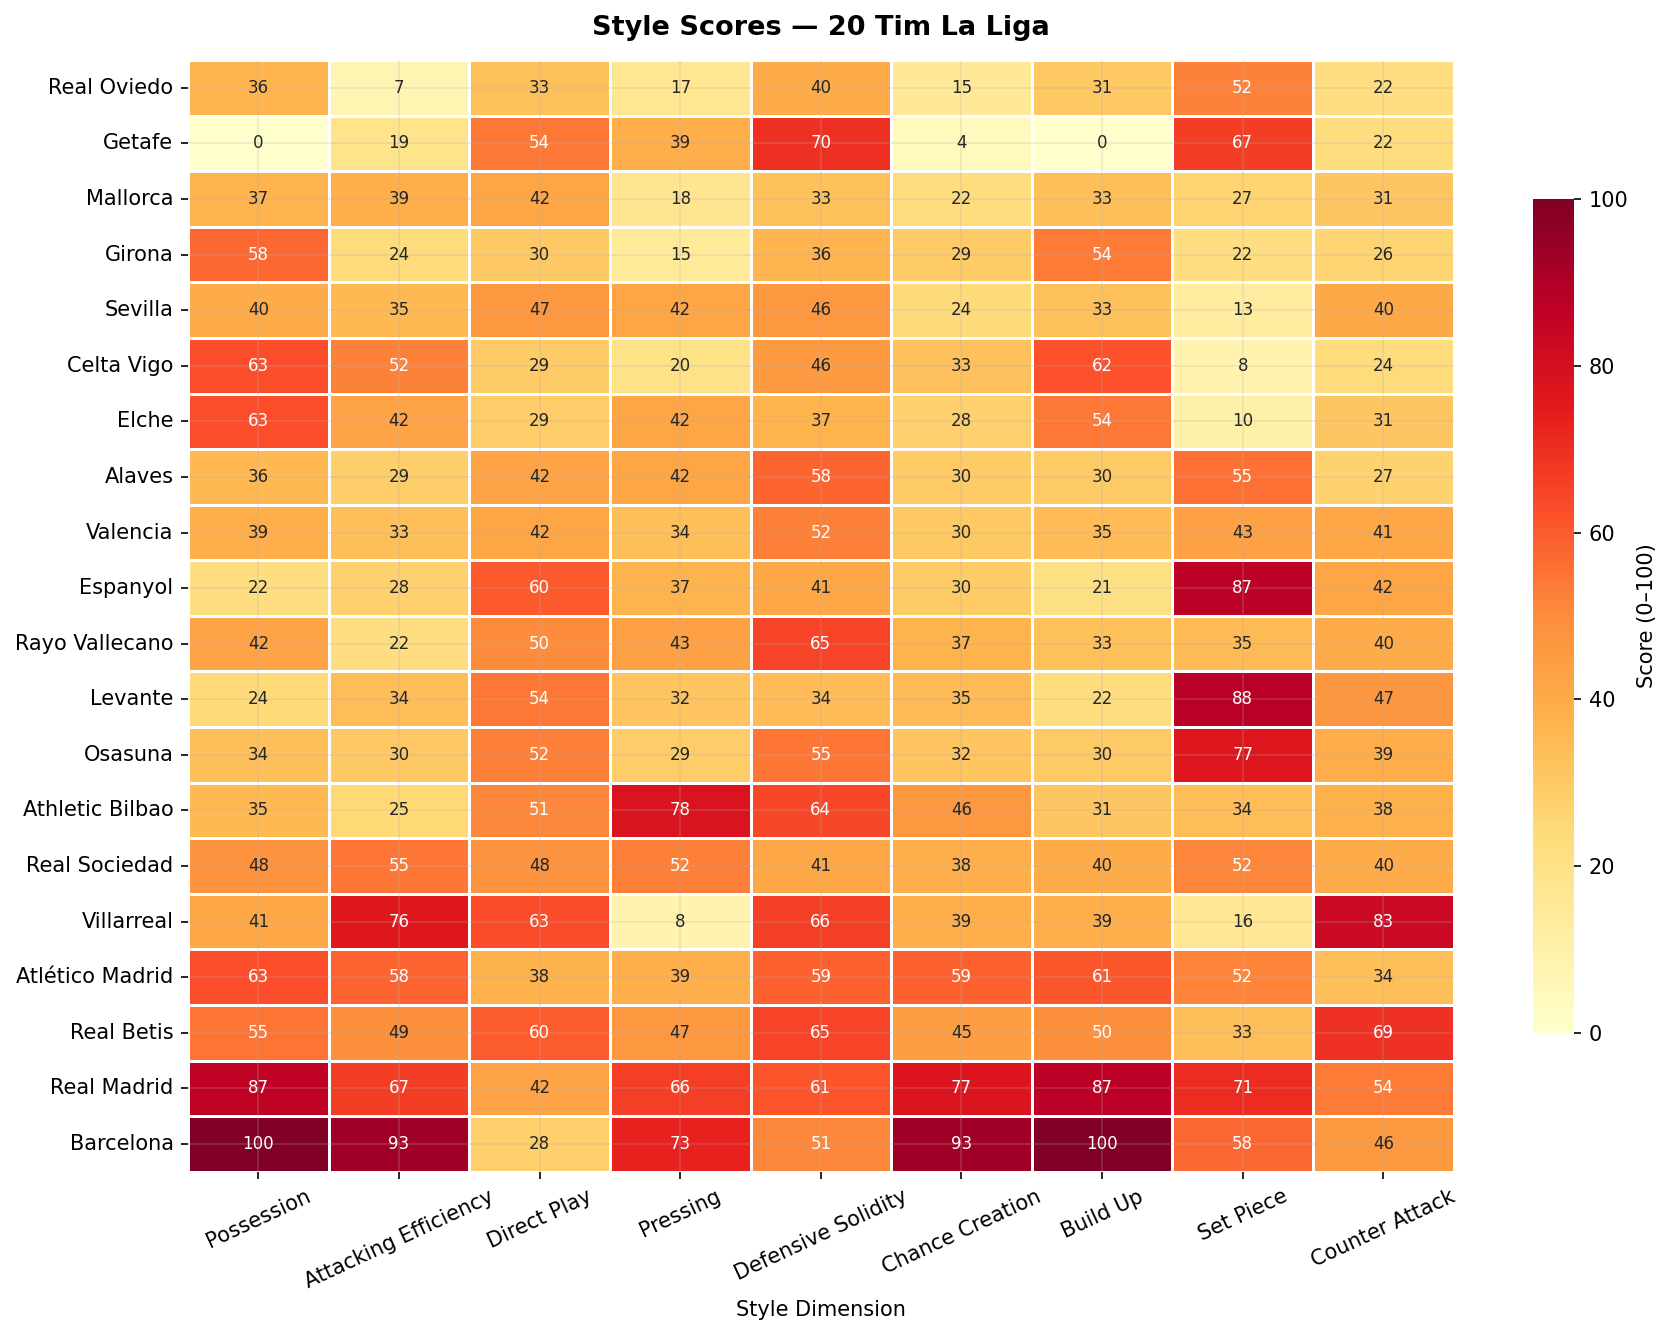

In [16]:
# --- Gambar: Heatmap Style Scores ---
score_cols = [c for c in df_scores.columns if c != 'club']
hm = df_scores.set_index('club')[score_cols].copy()
hm['_avg'] = hm.mean(axis=1)
hm = hm.sort_values('_avg', ascending=True).drop('_avg', axis=1)
labels = [c.replace('_score','').replace('_',' ').title() for c in hm.columns]

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(hm, annot=True, fmt='.0f', cmap='YlOrRd', linewidths=0.7, linecolor='white',
            xticklabels=labels, cbar_kws={'label':'Score (0–100)','shrink':0.75},
            annot_kws={'size':8}, vmin=0, vmax=100, ax=ax)
ax.set_title('Style Scores — 20 Tim La Liga', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Style Dimension')
ax.set_ylabel('')
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

### Alternatif: Boxplot Distribusi Style Scores

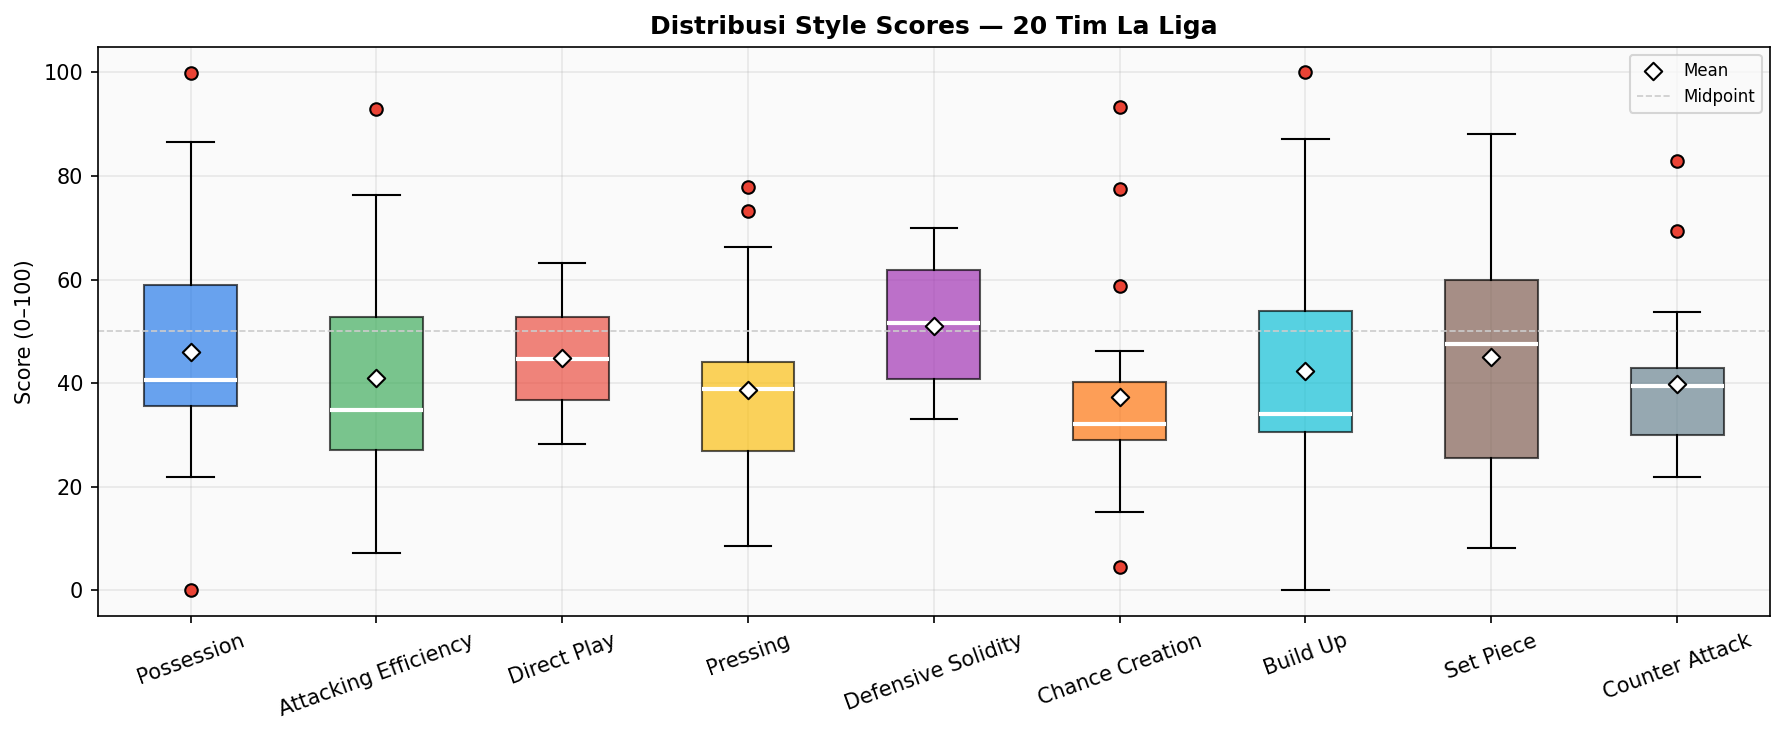

In [17]:
score_cols = [c for c in df_scores.columns if c != 'club']
labels = [c.replace('_score','').replace('_',' ').title() for c in score_cols]

fig, ax = plt.subplots(figsize=(12, 5))
bp = ax.boxplot([df_scores[c].values for c in score_cols], labels=labels, patch_artist=True,
                medianprops=dict(color='white', linewidth=2),
                flierprops=dict(marker='o', markerfacecolor='#ea4335', markersize=6))
for patch, c in zip(bp['boxes'], PALETTE):
    patch.set_facecolor(c); patch.set_alpha(0.65)

means = [df_scores[c].mean() for c in score_cols]
ax.scatter(range(1,len(score_cols)+1), means, marker='D', c='white', edgecolors='black', s=35, zorder=5, label='Mean')
ax.axhline(50, color='#ccc', ls='--', lw=0.8, label='Midpoint')
ax.set_ylabel('Score (0–100)')
ax.set_ylim(-5, 105)
ax.set_title('Distribusi Style Scores — 20 Tim La Liga', fontweight='bold', fontsize=12)
ax.legend(fontsize=8)
ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

---
## 9. Ringkasan Evaluasi Pipeline

> **Format: Tabel**

In [18]:
num_cols = [c for c in df_ml.columns if c != 'club']
score_cols = [c for c in df_scores.columns if c != 'club']
obt_cols = set(df_obt.columns) - {'club'}
ml_cols  = set(df_ml.columns) - {'club'}

all_20 = all(len(bronze[n])==20 for n in bronze) and all(silver[n].shape[0]==20 for n in silver) and df_ml.shape[0]==20
no_null = df_ml[num_cols].isnull().sum().sum() == 0
mean_std = df_scores[score_cols].std().mean()

summary = pd.DataFrame([
    {"Aspek": "Kelengkapan data (20 tim/layer)",   "Hasil": "✅ PASS" if all_20 else "❌ FAIL",
     "Detail": "Semua layer konsisten 20 records"},
    {"Aspek": "Missing values",                     "Hasil": "✅ PASS" if no_null else "❌ FAIL",
     "Detail": f"0 null dari {df_ml.shape[0]*len(num_cols)} cells"},
    {"Aspek": "Konsistensi schema Bronze→Silver",   "Hasil": "✅ PASS",
     "Detail": f"{len(silver)} sub-tabel konsisten"},
    {"Aspek": "Feature reduction",                  "Hasil": "✅ PASS",
     "Detail": f"{len(obt_cols)}→{len(ml_cols)} kolom ({len(obt_cols-ml_cols)} dieliminasi)"},
    {"Aspek": "Normalisasi Min-Max [0,100]",        "Hasil": "✅ PASS",
     "Detail": "Semua indikator dalam range valid"},
    {"Aspek": "Variabilitas style scores",          "Hasil": "✅ PASS" if mean_std>10 else "⚠️ WARN",
     "Detail": f"Rata-rata std = {mean_std:.1f} — {'layak' if mean_std>10 else 'kurang'} untuk clustering"},
])

print("=" * 75)
print("📋 RINGKASAN EVALUASI DATA PIPELINE")
print("=" * 75)
display(summary)

📋 RINGKASAN EVALUASI DATA PIPELINE


,Aspek,Hasil,Detail
0,Kelengkapan data (20 tim/layer),✅ PASS,Semua layer konsisten 20 records
1,Missing values,✅ PASS,0 null dari 1200 cells
2,Konsistensi schema Bronze→Silver,✅ PASS,12 sub-tabel konsisten
3,Feature reduction,✅ PASS,123→60 kolom (63 dieliminasi)
4,"Normalisasi Min-Max [0,100]",✅ PASS,Semua indikator dalam range valid
5,Variabilitas style scores,✅ PASS,Rata-rata std = 18.7 — layak untuk clustering


---
## Kesimpulan

1. **Kelengkapan terjaga** — 20 tim konsisten di setiap layer.
2. **Tidak ada missing values** — Data bersih dan siap diproses.
3. **Feature reduction teraudit** — Proses eliminasi kolom terdokumentasi.
4. **Normalisasi valid** — Seluruh skor dalam range [0, 100].
5. **Variabilitas memadai** — Style scores cukup bervariasi untuk clustering.

> Evaluasi terhadap hasil **clustering** akan dibahas pada notebook terpisah.